# 01 — Forecasting data and training-period exploration

**Objective:** load the frozen snapshots, document variable definitions and examine the training period. No model is trained in this notebook.

NVIDIA is the target; SPY and XLK provide possible market/sector context. The final 2025 test period is excluded from this exploration.


In [1]:
from pathlib import Path
import json
import pandas as pd
import plotly.graph_objects as go
from market_forecasting.data import load_training_panel
root = Path.cwd()
if not (root / 'configs/nvda.json').exists():
    root = root.parent
config = json.loads((root / 'configs/nvda.json').read_text())
panel = load_training_panel(root, config)
stock = panel[config['target_ticker']]
pd.DataFrame({s: {'rows': len(f), 'first': str(f.index.min().date()), 'last': str(f.index.max().date())} for s, f in panel.items()}).T


,rows,first,last
NVDA,2014,2015-01-02,2022-12-30
SPY,2014,2015-01-02,2022-12-30
XLK,2014,2015-01-02,2022-12-30


## Observation and variable definitions
One trading session: opening, highest, lowest and closing prices plus trading volume. `adj_close` is retained separately from `close`. The modelling target is split-adjusted Close; see [data conventions](../docs/DATA_CONVENTIONS.md).


In [2]:
stock.head()


,high,close,volume,open,low,adj_close
date,,,,,,
2015-01-02,0.50700,0.50325,113680000,0.50325,0.49525,0.481884
2015-01-05,0.50475,0.49475,197952000,0.50325,0.49250,0.473745
2015-01-06,0.49600,0.47975,197764000,0.49550,0.47925,0.459381
2015-01-07,0.48750,0.47850,321808000,0.48325,0.47700,0.458185
2015-01-08,0.49950,0.49650,283780000,0.48400,0.48375,0.475420


## NVIDIA training-period price history
This is the vendor's split-adjusted close, not the original historical dollar quote. We do not apply the split a second time.


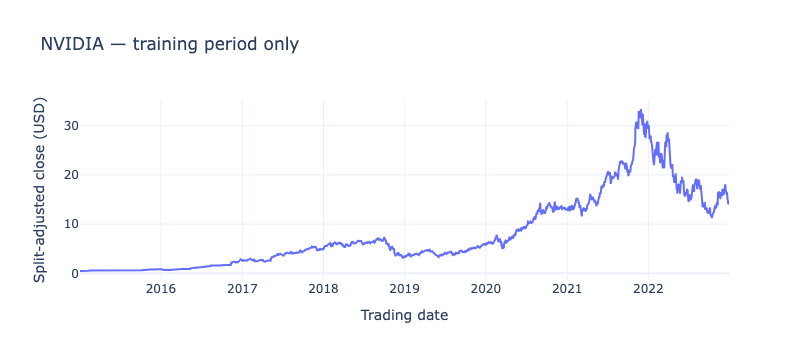

In [3]:
fig = go.Figure(go.Scatter(x=stock.index, y=stock['close'], name='NVDA close'))
fig.update_layout(title='NVIDIA — training period only', xaxis_title='Trading date', yaxis_title='Split-adjusted close (USD)', template='plotly_white')
fig.show()


## Compare historical price paths
Rebase each series to 100 on the first training date for a descriptive comparison. This chart uses close, not a dividend-reinvested total-return series, and does not establish forecasting performance.


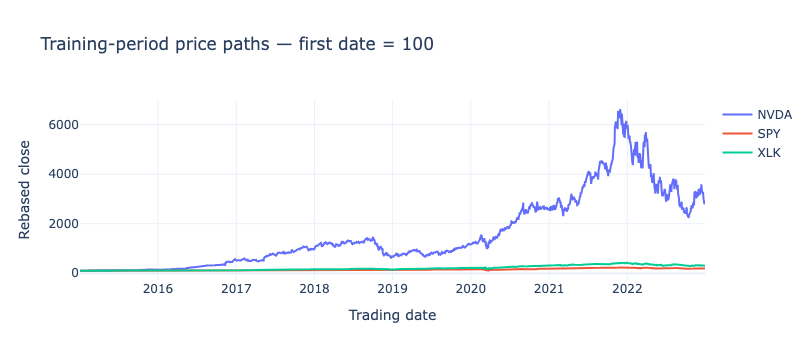

In [4]:
comparison = go.Figure()
for symbol, frame in panel.items():
    comparison.add_scatter(x=frame.index, y=100 * frame['close'] / frame['close'].iloc[0], name=symbol)
comparison.update_layout(title='Training-period price paths — first date = 100', xaxis_title='Trading date', yaxis_title='Rebased close', template='plotly_white')
comparison.show()


## Methodological interpretation
Each observation represents one trading session; the forecasting target is the following session's split-adjusted Close. Chronological ordering preserves forecast-time availability. Exploration is restricted to training observations to avoid using validation or test behaviour to guide initial data analysis.

Retrospective split adjustment maintains price continuity across splits but differs from original historical quotes. Agreement between instrument date indexes does not establish calendar completeness: all series could omit the same session. Exchange-calendar coverage is therefore audited separately.

**Subsequent implementation:** [notebook 02](02_dataset_and_naive_baseline.ipynb) constructs development windows and evaluates the naive validation baseline. This notebook remains limited to training-period exploration. See [progress](../docs/PROGRESS.md) for outstanding work.
